# Exercise 04

## Author Roohullah Amin

In [1]:
setwd = "Desktop/Environmental change/Lab/Ex_04"

### 1. Install and Load the libraries

In [5]:
install.packages("rgbif")
install.packages("dplyr")
install.packages("terra")
install.packages("geodata")
install.packages("randomForest")
install.packages("pROC")

Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

also installing the dependencies ‘sys’, ‘askpass’, ‘triebeard’, ‘openssl’, ‘curl’, ‘urltools’, ‘httpcode’, ‘httr’, ‘plyr’, ‘crul’, ‘whisker’, ‘oai’, ‘tibble’, ‘wk’


Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

also installing the dependencies ‘generics’, ‘tidyselect’


Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)



In [2]:
library(rgbif)
library(dplyr)
library(terra)
library(geodata)
library(randomForest)
library(pROC)
set.seed(123)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


terra 1.8.86

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:dplyr’:

    combine


Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




### 2. European hedgehog presence data from GBIF

In [9]:

hedgehog_key <- name_backbone(name = "Erinaceus europaeus")$usageKey

occ_raw <- occ_search(
  taxonKey      = hedgehog_key,
  hasCoordinate = TRUE,
  limit         = 20000
)

occ <- occ_raw$data %>%
  dplyr::select(decimalLatitude, decimalLongitude, year, basisOfRecord) %>%
  dplyr::filter(!is.na(decimalLatitude), !is.na(decimalLongitude)) %>%
  dplyr::filter(decimalLatitude != 0 | decimalLongitude != 0)

hedgehog_pres <- vect(
  occ,
  geom = c("decimalLongitude", "decimalLatitude"),
  crs  = "EPSG:4326"
)

hedgehog_pres

# Save as shapefile
writeVector(hedgehog_pres, "hedgehog_presence_ger.shp", overwrite = TRUE)

 class       : SpatVector 
 geometry    : points 
 dimensions  : 20000, 2  (geometries, attributes)
 extent      : -25.33138, 176.1957, -46.36783, 67.29334  (xmin, xmax, ymin, ymax)
 coord. ref. : lon/lat WGS 84 (EPSG:4326) 
 names       :  year     basisOfRecord
 type        : <int>             <chr>
 values      :  2025 HUMAN_OBSERVATION
                2025 HUMAN_OBSERVATION
                2025 HUMAN_OBSERVATION

In [5]:
hedgehog_pres_ger <- vect("/home/aminr/Desktop/Environmental change/hedgehog_presence_ger.shp")

In [13]:
install.packages("sf")


Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

also installing the dependency ‘s2’




In [14]:
install.packages("s2")
install.packages("rnaturalearth")

Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

Installing package into ‘/home/aminr/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)



### 3. Study area: Germany extent

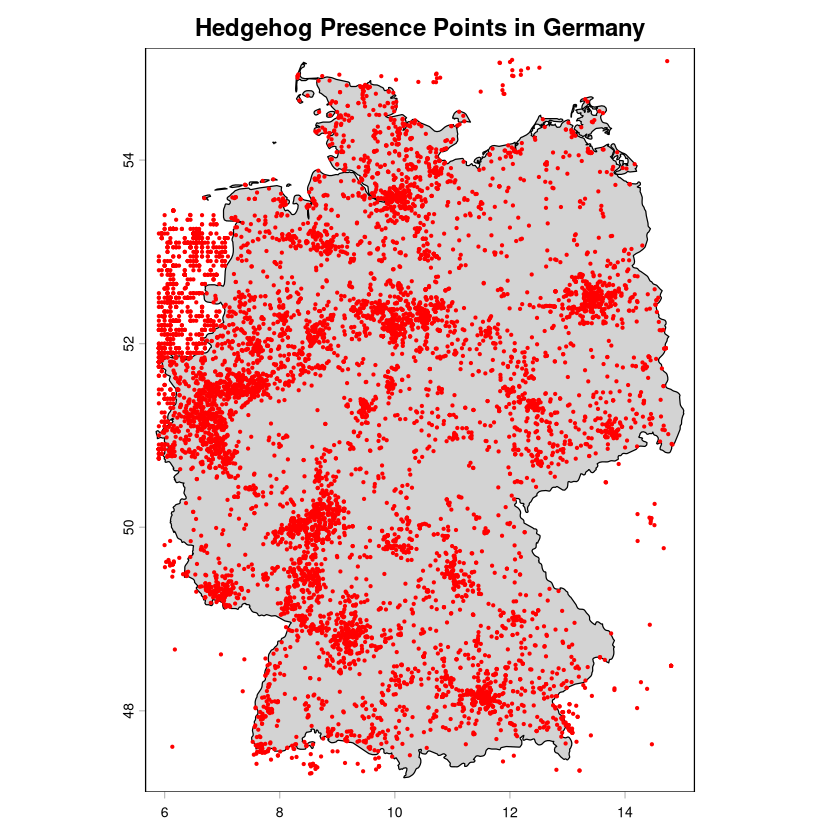

In [18]:
# devtools::as.package()
library(rnaturalearth)
library(sf)
library(terra)
# Germany extent
ger_extent <- ext(5.9, 15.0, 47.3, 55.1)
hedgehog_pres_ger <- crop(hedgehog_pres_ger, ger_extent)

# Get Germany boundary polygon
ger_boundary_sf <- ne_countries(scale = 10, country = "Germany", returnclass = "sf")

# In terra SpatVector changing
ger_boundary <- vect(ger_boundary_sf)

# Plot
plot(ger_boundary, main="Hedgehog Presence Points in Germany", col="lightgrey", border="black")
points(hedgehog_pres_ger, col="red", pch=20, cex=0.5)

### 4. Get WorldClim data - Bioclim

In [19]:
bio_current <- worldclim_global(var = "bio", res = 10, path = "data")

bio_current_ger <- crop(bio_current, ger_extent)

bio_current_ger <- bio_current_ger[[c("wc2.1_10m_bio_1", "wc2.1_10m_bio_5", "wc2.1_10m_bio_6", "wc2.1_10m_bio_12")]]

bio_current_ger

class       : SpatRaster 
size        : 47, 55, 4  (nrow, ncol, nlyr)
resolution  : 0.1666667, 0.1666667  (x, y)
extent      : 5.833333, 15, 47.33333, 55.16667  (xmin, xmax, ymin, ymax)
coord. ref. : lon/lat WGS 84 (EPSG:4326) 
source(s)   : memory
names       : wc2.1_10m_bio_1, wc2.1_10m_bio_5, wc2.1_10m_bio_6, wc2.1_10m_bio_12 
min values  :        2.664614,        15.77625,        -9.10225,              485 
max values  :       10.796989,        25.38450,         1.20000,             1860 

### 5. Create the Pseudo-absences

In [20]:
pres_coords <- crds(hedgehog_pres_ger)

n_abs <- nrow(pres_coords)

bg_points <- spatSample(
  x = bio_current_ger[[1]],
  size = n_abs,
  method = "random",
  as.points = TRUE,
  na.rm = TRUE
)

bg_coords <- crds(bg_points)

Warning message:
“[spatSample] requested sample size is larger than the number of cells”
Warning message:
“[spatSample] fewer cells returned than requested”


In [21]:
n_abs
ncell(bio_current_ger[[1]])

[1] 9461

[1] 2585

### 6. Extract environmental predictors for presence and pseudo-absences points

In [22]:
pres_env <- terra::extract(bio_current_ger, pres_coords)
abs_env  <- terra::extract(bio_current_ger, bg_coords)

pres_df <- data.frame(presence = 1, pres_env)
abs_df  <- data.frame(presence = 0, abs_env)

sdm_df <- rbind(pres_df, abs_df) %>% na.omit()

head(sdm_df)

,presence,wc2.1_10m_bio_1,wc2.1_10m_bio_5,wc2.1_10m_bio_6,wc2.1_10m_bio_12
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,9.678917,22.35225,0.17125,805
2,1,9.274593,22.90300,-1.30225,720
3,1,9.211448,21.36550,-0.16325,829
4,1,9.708479,22.60600,-0.09775,835
5,1,9.140115,22.96075,-1.48200,633
6,1,9.942657,22.67575,0.13950,720


### 7. Organize the data into train and testing 

In [23]:
set.seed(123)
n <- nrow(sdm_df)
train_idx <- sample(seq_len(n), size = round(0.7 * n)) # 70 % of the whole dataset

train_data <- sdm_df[train_idx, ]
test_data  <- sdm_df[-train_idx, ] # 30% of the dataset

train_data$presence <- as.factor(train_data$presence)
test_data$presence  <- as.factor(test_data$presence)


### 8. Fit the randomForest model

In [24]:
rf_model <- randomForest(
presence ~ .,
data = train_data,
ntree = 500,
importance = TRUE
)

rf_model

# 
rf_model$confusion


Call:
 randomForest(formula = presence ~ ., data = train_data, ntree = 500,      importance = TRUE) 
               Type of random forest: classification
                     Number of trees: 500
No. of variables tried at each split: 2

        OOB estimate of  error rate: 20.02%
Confusion matrix:
    0    1 class.error
0 505 1145   0.6939394
1 513 6118   0.0773639

,0,1,class.error
0,505,1145,0.6939394
1,513,6118,0.0773639


### 9. Model evaluation (AUC)

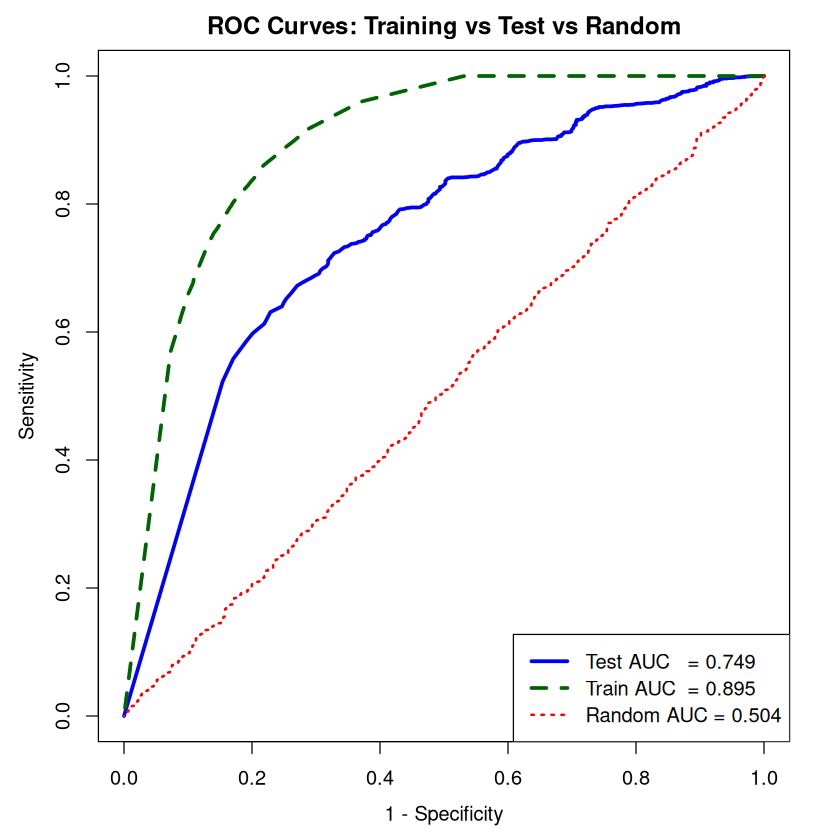

In [25]:
library(pROC)

## 0. Make sure response is a simple 0/1 factor
train_data$presence <- factor(train_data$presence, levels = c(0, 1))
test_data$presence  <- factor(test_data$presence,  levels = c(0, 1))

## 1. TRAIN ROC & AUC
train_pred_prob <- predict(
  rf_model,
  newdata = train_data,
  type   = "prob"
)[, 2]   # 2nd column = class "1"

roc_train <- roc(response = train_data$presence,
                 predictor = train_pred_prob,
                 quiet = TRUE)
auc_train <- auc(roc_train)

## 2. TEST ROC & AUC
test_pred_prob <- predict(
  rf_model,
  newdata = test_data,
  type   = "prob"
)[, 2]

roc_test <- roc(response = test_data$presence,
                predictor = test_pred_prob,
                quiet = TRUE)
auc_test <- auc(roc_test)

## 3. RANDOM PREDICTIONS ROC & AUC (true random classifier)
set.seed(123)
rand_prob <- runif(nrow(test_data))

roc_rand <- roc(response = test_data$presence,
                predictor = rand_prob,
                quiet = TRUE)
auc_rand <- auc(roc_rand)

## 4. PLOT ALL THREE (no duplicate diagonal)
plot(
  roc_test,
  col         = "blue",
  lwd         = 3,
  legacy.axes = TRUE,      # 0 → 1 on x-axis
  identity    = FALSE,     # DON'T draw pROC's default diagonal
  main        = "ROC Curves: Training vs Test vs Random"
)

lines(roc_train, col = "darkgreen", lwd = 3, lty = 2)
lines(roc_rand,  col = "red",       lwd = 2, lty = 3)

## If you *want* a single diagonal reference line, keep this:
#abline(a = 0, b = 1, col = "grey", lwd = 1, lty = 3)

legend(
  "bottomright",
  legend = c(
    paste("Test AUC   =", round(auc_test,  3)),
    paste("Train AUC  =", round(auc_train, 3)),
    paste("Random AUC =", round(auc_rand, 3))
  ),
  col = c("blue", "darkgreen", "red"),
  lwd = c(3, 3, 2),
  lty = c(1, 2, 3),
  bg  = "white"
)

### 10. Variable Importance

,0,1,MeanDecreaseAccuracy,MeanDecreaseGini
wc2.1_10m_bio_1,-36.81517,94.38321,97.88376,509.1691
wc2.1_10m_bio_5,-57.08590,93.96484,89.75140,391.3013
wc2.1_10m_bio_6,-49.80688,100.42223,102.16070,436.6516
wc2.1_10m_bio_12,-77.93989,132.69146,123.00599,356.0135


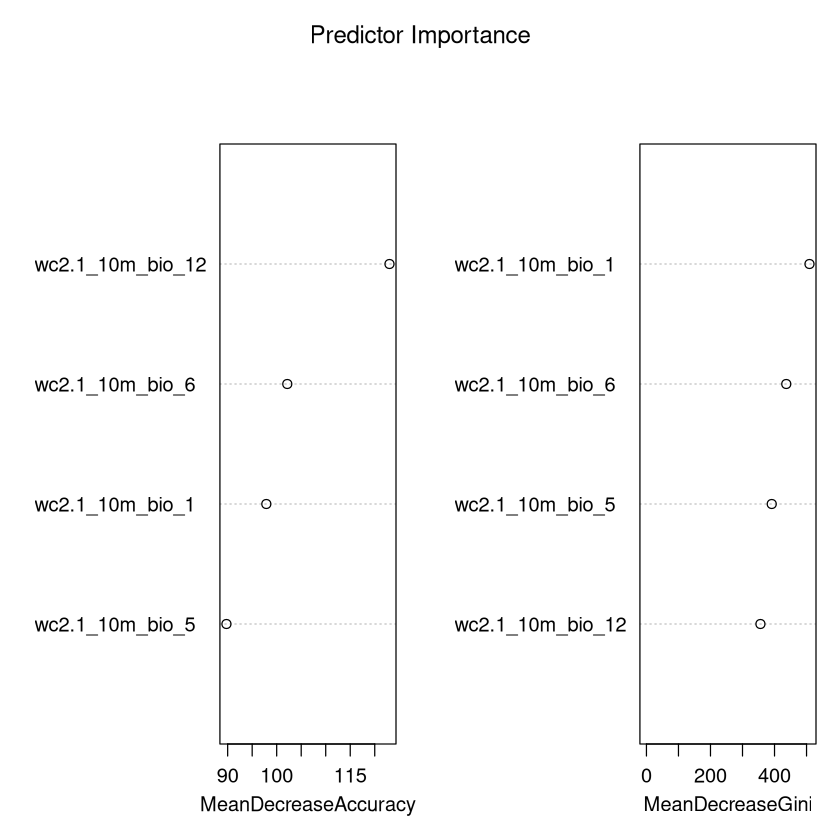

In [28]:
varImpPlot(rf_model, main = "Predictor Importance")

# Print variable importance values as text
importance(rf_model)

### 11. Prediction for current distribution of habitat suitability

class       : SpatRaster 
size        : 47, 55, 1  (nrow, ncol, nlyr)
resolution  : 0.1666667, 0.1666667  (x, y)
extent      : 5.833333, 15, 47.33333, 55.16667  (xmin, xmax, ymin, ymax)
coord. ref. : lon/lat WGS 84 (EPSG:4326) 
source(s)   : memory
name        : X1 
min value   :  0 
max value   :  1 

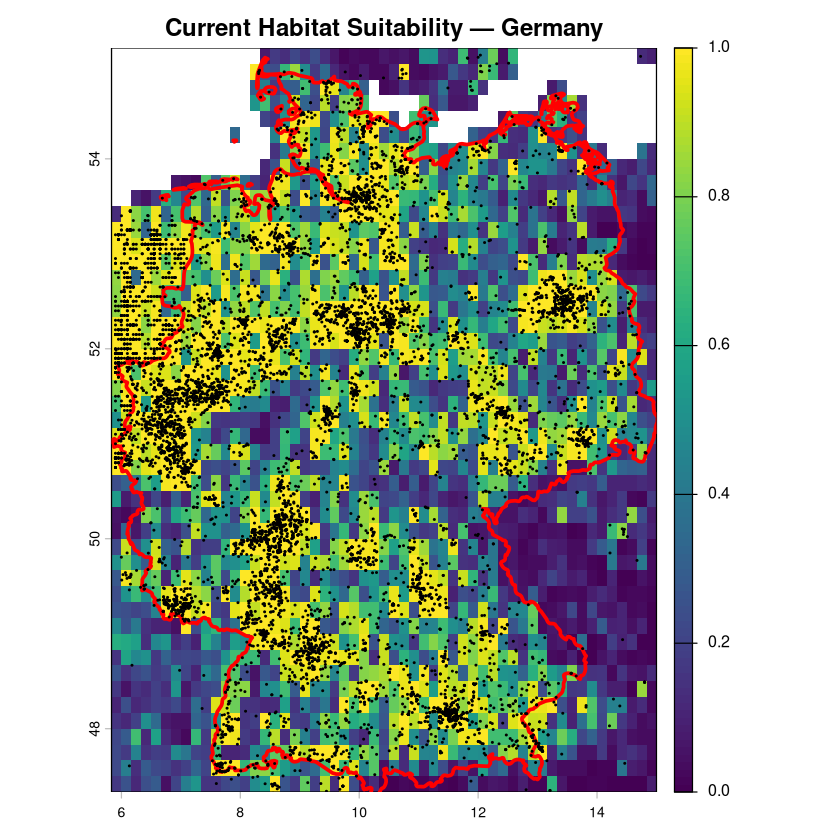

In [29]:
pred_current <- terra::predict(
object = bio_current_ger,
model  = rf_model,
type   = "prob",
index  = 2
)

pred_current

plot(pred_current, main = "Current Habitat Suitability — Germany")

# Add Germany border outline
plot(ger_boundary, add = TRUE, border = "red", lwd = 3)

# Add hedgehog presence points
points(hedgehog_pres_ger, pch = 20, cex = 0.3)